# Hypothesis And Inference

## Hypothesis Testing
Hypothesis testing in ststistics is a formal process used to determine whether the sample data provides enough evidence to specific research.

- **Null Hypothesis($H_0$)** : The dafault position i.e nothing special is happening. Example Coin is fair (P = 0.50)
- **Alternative Hypothesis($H_1$)** : What we want to check against or the effect we want to prove. Example Coin is not fair (P $\neq$ 0.5) 

In [2]:
# Import libraries

import math
import statistics as stats
import statsmodels as statm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Create function of Normal Probability Distributive Function 

def normal_pdf(x, mu=0, sigma=1):
    return math.exp(-(x - mu) ** 2 / 2 / sigma ** 2) / (math.sqrt(2 * math.pi) * sigma)

# Create function of Normal Cumulative Density Function

def normal_cdf(x, mu=0, sigma=1):
    return (1 + math.erf((x - mu) / math.sqrt(2) / sigma)) / 2

# Create function of Inverse of Normal Probability Distributive Function
# Find x where normal_cdf(x) approximate to p, using binary search

def inverse_normal_cdf(p, mu=0, sigma=1, tolerance=0.00001):
    if mu != 0 or sigma != 1:
        return mu + sigma * inverse_normal_cdf(p, tolerance=tolerance)
    low_z, hi_z = -10.0, 10.0
    while hi_z - low_z > tolerance:
        mid_z = (low_z + hi_z) / 2
        if normal_cdf(mid_z) < p:
            low_z = mid_z
        else:
            hi_z = mid_z
    return mid_z

### Flipping a Coin Example:

Before a local cricket tournament, the organisers want to check if the toss coin is fair.
- **$H_0$:** the coin is fair $\to$ probability of Heads p = 0.5
- **$H_1$:** the coin is not fair $\to$ p $\neq$ 0.5

We toss it n = 100 times and count the Heads (X). X is a **Binomial(n, p)** variable, which we can approximate with a **normal distribution**:
- mean = **$\mu$** = np
- standard deviation = **$\sigma$** = $\sqrt{np(1-p)}$

In [5]:
# Returns mu and sigma for a Binomial(n, p)

def normal_approximation_to_binomial(n, p):
    mu = n * p
    sigma = math.sqrt(n * p * (1 - p))
    return mu, sigma

mu_0, sigma_0 = normal_approximation_to_binomial(100, 0.5)
print("If the coin is fair: mean =", mu_0, ", standard deviation =", sigma_0)

If the coin is fair: mean = 50.0 , standard deviation = 5.0


In [6]:
# the normal cdf is the probability of being below a value

normal_probability_below = normal_cdf

# Above lo = not below lo
def normal_probability_above(lo, mu=0, sigma=1):
    return 1 - normal_cdf(lo, mu, sigma)

# Between = below hi, but not below lo
def normal_probability_between(lo, hi, mu=0, sigma=1):
    return normal_cdf(hi, mu, sigma) - normal_cdf(lo, mu, sigma)

# Outside = not between
def normal_probability_outside(lo, hi, mu=0, sigma=1):
    return 1 - normal_probability_between(lo, hi, mu, sigma)

print("P(X < 45)= ", round(normal_probability_below(45, mu_0, sigma_0), 3))
print("P(X > 55)= ", round(normal_probability_above(55, mu_0, sigma_0), 3))
print("P(45 < X < 55)= ", round(normal_probability_between(45, 55, mu_0, sigma_0), 3))
print("P(outside 45-55)= ", round(normal_probability_outside(45, 55, mu_0, sigma_0), 3))

P(X < 45)=  0.159
P(X > 55)=  0.159
P(45 < X < 55)=  0.683
P(outside 45-55)=  0.317


In [8]:
# Going backwards, finding the bounds
# Between which two values will X fall 95% of the time (if the coin is fair)

# Returns z such that P(Z <= z) = probability
def normal_upper_bound(probability, mu=0, sigma=1):
    return inverse_normal_cdf(probability, mu, sigma)

# Returns z such that P(Z >= z) = probability
def normal_lower_bound(probability, mu=0, sigma=1):
    return inverse_normal_cdf(1 - probability, mu, sigma)

# Returns the bounds (centred on the mean) that contain the given probability
def normal_two_sided_bounds(probability, mu=0, sigma=1):
    tail_probability = (1 - probability) / 2          # split the rest equally into two tails
    upper_bound = normal_lower_bound(tail_probability, mu, sigma)
    lower_bound = normal_upper_bound(tail_probability, mu, sigma)
    return lower_bound, upper_bound

lo, hi = normal_two_sided_bounds(0.95, mu_0, sigma_0)
print(f"95% of the time, a fair coin gives between {lo:.1f} and {hi:.1f} Heads in 100 tosses")

95% of the time, a fair coin gives between 40.2 and 59.8 Heads in 100 tosses


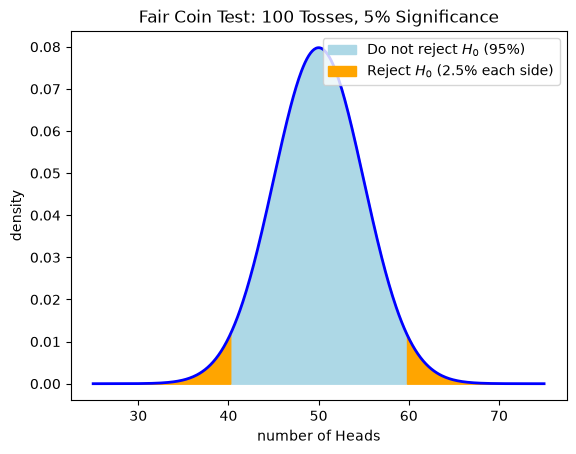

In [12]:
# Our test rule (at 5% significance)
# If Heads < 40.2 or Heads > 59.8, reject H₀ (the coin looks unfair).
# Otherwise, we cannot say the coin is unfair.

xs = [x / 10 for x in range(250, 751)]
ys = [normal_pdf(x, mu_0, sigma_0) for x in xs]

plt.plot(xs, ys, color='blue', linewidth=2)
plt.fill_between([x for x in xs if lo <= x <= hi],
                 [normal_pdf(x, mu_0, sigma_0) for x in xs if lo <= x <= hi],
                 color='lightblue', label=r"Do not reject $H_0$ (95%)")
plt.fill_between([x for x in xs if x <= lo],
                 [normal_pdf(x, mu_0, sigma_0) for x in xs if x <= lo],
                 color='orange', label=r"Reject $H_0$ (2.5% each side)")
plt.fill_between([x for x in xs if x >= hi],
                 [normal_pdf(x, mu_0, sigma_0) for x in xs if x >= hi],
                 color='orange')
plt.title("Fair Coin Test: 100 Tosses, 5% Significance")
plt.xlabel("number of Heads")
plt.ylabel("density")
plt.legend(loc="upper right")
plt.show()

### Types of Error:
In hypothesis testing, we make a decision about a claim (the null hypothesis) using sample data, and since we never observe the entire population, there is always a chance of making an incorrect decision. There are two main types of errors.

- A **Type I error** happens when we reject the null hypothesis even though it is actually true. In simple terms, it is a “false alarm”: we conclude that something is happening when it really isn’t, like a medical test indicating that a healthy person has a disease. The probability of making this error is called the **significance level**, denoted by $\alpha$ (alpha), and is usually set to 0.05 (5%).
- A **Type II error** happens when we fail to reject the null hypothesis even though it is actually false. This is a “missed detection”: we conclude that nothing is happening when something really is, like a test saying a sick person is healthy. The probability of this error is denoted by $\beta$ (beta), and 1 − $\beta$ is called the **power of the test**, which indicates how well the test detects a real effect.




In [13]:
# bounds assuming the coin is fair (p = 0.5)
lo, hi = normal_two_sided_bounds(0.95, mu_0, sigma_0)

# the real mean and sigma if p is actually 0.6
mu_1, sigma_1 = normal_approximation_to_binomial(100, 0.6)

# Type 2 error = X still falls inside our "don't reject" range
type_2_probability = normal_probability_between(lo, hi, mu_1, sigma_1)
power = 1 - type_2_probability
print(f"Power with 100 tosses = {power:.3f}")

Power with 100 tosses = 0.516


In [15]:
# Power of test

def power_of_test(n, true_p, significance=0.05):
    mu0, s0 = normal_approximation_to_binomial(n, 0.5)
    lo, hi = normal_two_sided_bounds(1 - significance, mu0, s0)
    mu1, s1 = normal_approximation_to_binomial(n, true_p)
    return 1 - normal_probability_between(lo, hi, mu1, s1)

for n in [50, 100, 200, 500, 1000]:
    print(f"n = {n:>4} tosses -> power = {power_of_test(n, 0.6):.3f}")

n =   50 tosses -> power = 0.289
n =  100 tosses -> power = 0.516
n =  200 tosses -> power = 0.812
n =  500 tosses -> power = 0.995
n = 1000 tosses -> power = 1.000


### One-sided test
Sometimes we only care about **one direction**. Example: the organisers only worry if the coin favours **Heads**.

- **$H_0$:** p $\le$ 0.5 (not biased towards Heads)
- **$H_1$:** p > 0.5

In [16]:
hi_one_sided = normal_upper_bound(0.95, mu_0, sigma_0)
print(f"One-sided rule: reject H₀ if Heads > {hi_one_sided:.1f}")

type_2_probability = normal_probability_below(hi_one_sided, mu_1, sigma_1)
print(f"Power of one-sided test (true p = 0.6) = {1 - type_2_probability:.3f}")

One-sided rule: reject H₀ if Heads > 58.2
Power of one-sided test (true p = 0.6) = 0.642
